# Data download practice

This material is based in the **CABANA BiotrAIn**, Concepts, approaches and applications of Artificial Intelligence in bioscience program The cancer dataset example was develovep by Juan Bizzoto https://github.com/jbzt/cancer_data_for_cluster_and_classification
 in particular here we address the section: "how this data was created?"
https://rpubs.com/jbzt/914994.


We are going to interact with "https://xenabrowser.net/" downloading data from this notebook. Here are some detailed [tutorials](https://xena.ucsc.edu/) about how to use the web tools of Xena browsers

In [23]:
# import libraries
import pandas as pd
import urllib.request

# Downloading TCGA data from UCSC Xena

This notebook demonstrates how to download gene expression, clinical phenotype, and survival data from the TCGA repository hosted by UCSC Xena.

TCGA cohorts are identified by standardized project abbreviations. Some commonly used examples are:

| Code | Cancer Type |
|--------|-------------|
| BRCA | Breast Invasive Carcinoma |
| PRAD | Prostate Adenocarcinoma |
| LUAD | Lung Adenocarcinoma |
| LUSC | Lung Squamous Cell Carcinoma |
| COAD | Colon Adenocarcinoma |
| READ | Rectum Adenocarcinoma |
| STAD | Stomach Adenocarcinoma |
| LIHC | Liver Hepatocellular Carcinoma |
| KIRC | Kidney Renal Clear Cell Carcinoma |
| KIRP | Kidney Renal Papillary Cell Carcinoma |
| OV | Ovarian Serous Cystadenocarcinoma |
| GBM | Glioblastoma Multiforme |
| LGG | Brain Lower Grade Glioma |
| SKCM | Skin Cutaneous Melanoma |
| PAAD | Pancreatic Adenocarcinoma |
| HNSC | Head and Neck Squamous Cell Carcinoma |
| BLCA | Bladder Urothelial Carcinoma |
| UCEC | Uterine Corpus Endometrial Carcinoma |
| CESC | Cervical Squamous Cell Carcinoma and Endocervical Adenocarcinoma |
| THCA | Thyroid Carcinoma |

For each TCGA cohort, three datasets are downloaded:

### 1. Gene Expression

RNA-seq expression matrix.

- Rows correspond to genes.
- Columns correspond to tumor samples.
- Expression values are normalized counts provided by UCSC Xena.

### 2. Clinical Phenotype

Clinical and demographic information for each patient.

Examples of available variables include:

- Age
- Gender
- Tumor stage
- Histological subtype
- Treatment information

### 3. Survival Data

Clinical outcome information used for survival analyses.

Important variables include:

- **OS**: Overall Survival event (1 = deceased, 0 = censored)
- **OS.time**: Overall Survival follow-up time (days)
- **DSS**: Disease-Specific Survival event
- **DSS.time**: Disease-Specific Survival time (days)
- **DFI**: Disease-Free Interval event (tumor recurrence)
- **DFI.time**: Time to recurrence (days)
- **PFI**: Progression-Free Interval event
- **PFI.time**: Time to progression, recurrence, or death (days)

For many TCGA studies, OS and PFI are the most complete endpoints and are commonly used in downstream analyses such as Kaplan-Meier survival curves and Cox proportional hazards models.

Additional TCGA project abbreviations can be found at:

- https://gdc.cancer.gov/resources-tcga-users/tcga-code-tables/tcga-study-abbreviations
- https://xenabrowser.net/datapages/

The code below downloads expression, phenotype, and survival data for the selected TCGA cohort.

In [24]:
# set wrl to download data
cancer = "PRAD"  # choose one type LUAD, PRAD, COAD, OV, GBM, etc.

base = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download"

urls = {
    "expression": f"{base}/TCGA.{cancer}.sampleMap%2FHiSeqV2.gz",
    "pheno": f"{base}/TCGA.{cancer}.sampleMap%2F{cancer}_clinicalMatrix",
    "survival": f"{base}/survival%2F{cancer}_survival.txt"
}



In [25]:
# file names
files = {
    "expression": f"{cancer}_expression.gz",
    "pheno": f"{cancer}_pheno.tsv",
    "survival": f"{cancer}_survival.tsv"
}

In [26]:
# download data
for key in urls:
    print(f"Downloading {key}...")
    urllib.request.urlretrieve(urls[key], files[key])


In [27]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#BRCA_exp = pd.read_csv("BRCA_expression.gz", sep="\t")
#BRCA_pheno = pd.read_csv("BRCA_pheno.tsv", sep="\t")
#BRCA_surv = pd.read_csv("BRCA_survival.tsv", sep="\t")

In [ ]:

PRAD_exp = pd.read_csv("PRAD_expression.gz", sep="\t")
PRAD_pheno = pd.read_csv("PRAD_pheno.tsv", sep="\t")
PRAD_surv = pd.read_csv("PRAD_survival.tsv", sep="\t")

In [28]:
PRAD_exp


,sample,TCGA-XJ-A83F-01,TCGA-G9-6348-01,TCGA-CH-5766-01,TCGA-EJ-A65G-01,TCGA-G9-6354-01,TCGA-EJ-5527-01,TCGA-HC-8213-01,TCGA-Y6-A9XI-01,TCGA-EJ-7125-11,...,TCGA-HC-A6AP-01,TCGA-EJ-7317-01,TCGA-YL-A8S9-01,TCGA-KK-A8IA-01,TCGA-G9-6356-01,TCGA-YL-A8SO-01,TCGA-J4-A67Q-01,TCGA-KK-A6E4-01,TCGA-KK-A7B0-01,TCGA-EJ-5511-01
0,ARHGEF10L,9.3554,8.8729,8.5581,9.2085,9.0514,8.7699,8.5544,9.0878,8.4893,...,9.9893,9.8316,9.5040,8.9076,9.6466,9.2028,9.6899,8.5757,9.7088,9.2665
1,HIF3A,5.1517,5.9049,4.9716,6.7795,5.3511,5.5978,3.7947,4.7539,6.9225,...,7.4100,6.3570,3.2686,4.8980,6.3657,5.8463,8.6302,5.4474,6.0986,5.8144
2,RNF17,0.0000,0.4008,0.7574,0.0000,0.0000,2.5554,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.4256,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,RNF10,12.4656,12.3538,12.2950,11.9701,12.5973,11.7983,12.4055,12.2347,11.5627,...,12.0948,12.2781,11.7392,12.1408,12.1805,12.5294,12.0489,11.9228,12.5002,11.9083
4,RNF11,11.1274,11.5348,11.9867,11.3146,11.3622,11.7041,11.4244,11.6855,12.0737,...,10.8254,11.2658,11.1787,11.2560,11.0933,11.2810,10.9468,10.2378,9.8724,10.8594
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20525,PTRF,12.4863,13.0699,11.2971,12.4049,12.2110,12.1727,10.9754,11.3438,12.9926,...,13.0993,12.7569,9.2944,11.0320,12.8678,12.4889,14.5251,11.7981,13.2078,13.0629
20526,BCL6B,6.8575,8.0385,6.0940,5.4921,5.7522,6.8433,5.2721,7.5973,5.7932,...,6.9578,6.7246,5.2412,5.3624,7.1674,7.1036,7.4815,5.6303,7.0009,6.2855
20527,GSTK1,11.1839,11.2972,10.3648,10.6787,11.2507,10.2521,10.9285,10.3427,11.4295,...,11.2209,10.7621,10.0220,10.5666,11.1354,10.9818,11.2397,9.9984,12.3209,10.8123
20528,SELP,8.0296,9.2337,7.6376,7.1290,6.4412,8.2910,7.7970,7.0854,7.6705,...,8.5739,7.9527,6.3400,6.8485,8.5368,8.0984,8.4003,7.2569,8.8266,7.9353


In [29]:
# Data are not the same, but still useful
column_name = 'TCGA-G3-A3CH-11'
if column_name in PRAD_exp.columns:
    print(f"La columna '{column_name}' SÍ está en el DataFrame PRAD_exp.")
else:
    print(f"La columna '{column_name}' NO está en el DataFrame PRAD_exp.")

La columna 'TCGA-G3-A3CH-11' NO está en el DataFrame PRAD_exp.


In [30]:

PRAD_pheno

,sampleID,_INTEGRATION,_PATIENT,_cohort,_primary_disease,_primary_site,additional_pharmaceutical_therapy,additional_radiation_therapy,age_at_initial_pathologic_diagnosis,bcr_followup_barcode,...,_GENOMIC_ID_TCGA_PRAD_PDMRNAseq,_GENOMIC_ID_TCGA_PRAD_miRNA_HiSeq,_GENOMIC_ID_TCGA_PRAD_RPPA,_GENOMIC_ID_TCGA_PRAD_gistic2,_GENOMIC_ID_TCGA_PRAD_exp_HiSeqV2_percentile,_GENOMIC_ID_TCGA_PRAD_PDMRNAseqCNV,_GENOMIC_ID_data/public/TCGA/PRAD/miRNA_HiSeq_gene,_GENOMIC_ID_TCGA_PRAD_mutation_bcm_gene,_GENOMIC_ID_TCGA_PRAD_mutation_curated_broad_gene,_GENOMIC_ID_TCGA_PRAD_exp_HiSeqV2_PANCAN
0,TCGA-2A-A8VL-01,TCGA-2A-A8VL-01,TCGA-2A-A8VL,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,51,TCGA-2A-A8VL-F71759,...,TCGA-2A-A8VL-01,TCGA-2A-A8VL-01,1487FD23-ED22-4942-86D6-CF19837F63B9,TCGA-2A-A8VL-01A-21D-A376-01,e10fe58f-7ceb-4ad8-bce3-5ffbefc05cb5,TCGA-2A-A8VL-01,TCGA-2A-A8VL-01,NaN,TCGA-2A-A8VL-01A-21D-A377-08,e10fe58f-7ceb-4ad8-bce3-5ffbefc05cb5
1,TCGA-2A-A8VO-01,TCGA-2A-A8VO-01,TCGA-2A-A8VO,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,57,TCGA-2A-A8VO-F71780,...,TCGA-2A-A8VO-01,TCGA-2A-A8VO-01,FF23B458-D1F8-4001-A8E3-7F8785435C76,TCGA-2A-A8VO-01A-11D-A376-01,20a779a3-04ab-4080-b11d-ed7b22fcd2da,TCGA-2A-A8VO-01,TCGA-2A-A8VO-01,NaN,TCGA-2A-A8VO-01A-11D-A377-08,20a779a3-04ab-4080-b11d-ed7b22fcd2da
2,TCGA-2A-A8VT-01,TCGA-2A-A8VT-01,TCGA-2A-A8VT,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,47,TCGA-2A-A8VT-F71798,...,TCGA-2A-A8VT-01,TCGA-2A-A8VT-01,931CEBFB-011C-4797-8E05-8012D3ADC601,TCGA-2A-A8VT-01A-11D-A376-01,2e80aebe-77b5-496c-bde9-494b9b94ee3f,TCGA-2A-A8VT-01,TCGA-2A-A8VT-01,NaN,TCGA-2A-A8VT-01A-11D-A377-08,2e80aebe-77b5-496c-bde9-494b9b94ee3f
3,TCGA-2A-A8VV-01,TCGA-2A-A8VV-01,TCGA-2A-A8VV,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,52,TCGA-2A-A8VV-F71800,...,TCGA-2A-A8VV-01,TCGA-2A-A8VV-01,443A2276-226E-4D27-936C-3B25B14E7121,TCGA-2A-A8VV-01A-11D-A376-01,45eca81f-9ce2-4de6-b970-65959d76398c,TCGA-2A-A8VV-01,TCGA-2A-A8VV-01,NaN,TCGA-2A-A8VV-01A-11D-A377-08,45eca81f-9ce2-4de6-b970-65959d76398c
4,TCGA-2A-A8VX-01,TCGA-2A-A8VX-01,TCGA-2A-A8VX,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,70,TCGA-2A-A8VX-F71804,...,TCGA-2A-A8VX-01,TCGA-2A-A8VX-01,1A003DC8-7045-4F90-A768-F2E88FE31242,TCGA-2A-A8VX-01A-11D-A376-01,0ff237d2-9283-44c7-bfae-c2020c73b94c,TCGA-2A-A8VX-01,TCGA-2A-A8VX-01,NaN,NaN,0ff237d2-9283-44c7-bfae-c2020c73b94c
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
561,TCGA-ZG-A9M4-01,TCGA-ZG-A9M4-01,TCGA-ZG-A9M4,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,65,TCGA-ZG-A9M4-F67945,...,TCGA-ZG-A9M4-01,TCGA-ZG-A9M4-01,691D3F9B-5F1D-4D41-B54E-ECC3D69DB7C2,TCGA-ZG-A9M4-01A-11D-A41J-01,9c1dbf62-a42a-4a60-84bb-98715d9a4b60,TCGA-ZG-A9M4-01,TCGA-ZG-A9M4-01,NaN,NaN,9c1dbf62-a42a-4a60-84bb-98715d9a4b60
562,TCGA-ZG-A9MC-01,TCGA-ZG-A9MC-01,TCGA-ZG-A9MC,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,69,TCGA-ZG-A9MC-F67960,...,TCGA-ZG-A9MC-01,TCGA-ZG-A9MC-01,70BAE419-1B3E-4245-831B-D8B87E9F019C,TCGA-ZG-A9MC-01A-31D-A41J-01,d992a3c1-fe30-4d15-a4e6-4e250e834da2,TCGA-ZG-A9MC-01,TCGA-ZG-A9MC-01,NaN,NaN,d992a3c1-fe30-4d15-a4e6-4e250e834da2
563,TCGA-ZG-A9N3-01,TCGA-ZG-A9N3-01,TCGA-ZG-A9N3,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,73,TCGA-ZG-A9N3-F68209,...,TCGA-ZG-A9N3-01,TCGA-ZG-A9N3-01,BC0DA73E-2A1F-4853-8AD0-FB8649A7FD48,TCGA-ZG-A9N3-01A-11D-A41J-01,2ee45f38-cb92-4e91-acea-e454a13f59d9,TCGA-ZG-A9N3-01,TCGA-ZG-A9N3-01,NaN,NaN,2ee45f38-cb92-4e91-acea-e454a13f59d9
564,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND,TCGA Prostate Cancer (PRAD),prostate adenocarcinoma,Prostate,NaN,NaN,55,TCGA-ZG-A9ND-F68219,...,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND-01,NaN,TCGA-ZG-A9ND-01A-11D-A41J-01,35a82435-e313-4206-b328-b2b1db736aef,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND-01,NaN,NaN,35a82435-e313-4206-b328-b2b1db736aef


In [31]:
print(PRAD_pheno.columns.tolist())

['sampleID', '_INTEGRATION', '_PATIENT', '_cohort', '_primary_disease', '_primary_site', 'additional_pharmaceutical_therapy', 'additional_radiation_therapy', 'age_at_initial_pathologic_diagnosis', 'bcr_followup_barcode', 'bcr_patient_barcode', 'bcr_sample_barcode', 'biochemical_recurrence', 'bone_scan_results', 'clinical_M', 'clinical_T', 'days_to_birth', 'days_to_bone_scan_performed', 'days_to_collection', 'days_to_death', 'days_to_diagnostic_computed_tomography_performed', 'days_to_diagnostic_mri_performed', 'days_to_first_biochemical_recurrence', 'days_to_initial_pathologic_diagnosis', 'days_to_last_followup', 'days_to_new_tumor_event_after_initial_treatment', 'days_to_psa', 'days_to_second_biochemical_recurrence', 'days_to_third_biochemical_recurrence', 'diagnostic_ct_abd_pelvis_performed', 'diagnostic_ct_abd_pelvis_result', 'diagnostic_mri_performed', 'diagnostic_mri_result', 'followup_case_report_form_submission_reason', 'followup_treatment_success', 'form_completion_date', 'gend

In [32]:

PRAD_surv

,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction,recurrencia_3y,recurrency_3y
7,TCGA-2A-AAYF-01,TCGA-2A-AAYF,0,1364,0.0,1364,0.0,1364.0,0,1364,NaN,False,False
8,TCGA-2A-AAYO-01,TCGA-2A-AAYO,0,1272,0.0,1272,0.0,1272.0,0,1272,NaN,False,False
10,TCGA-4L-AA1F-01,TCGA-4L-AA1F,0,350,0.0,350,0.0,350.0,0,350,NaN,False,False
12,TCGA-CH-5738-01,TCGA-CH-5738,0,212,0.0,212,0.0,212.0,0,212,NaN,False,False
13,TCGA-CH-5739-01,TCGA-CH-5739,0,671,0.0,671,0.0,671.0,0,671,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
555,TCGA-ZG-A9LM-01,TCGA-ZG-A9LM,0,378,0.0,378,0.0,378.0,0,378,NaN,False,False
557,TCGA-ZG-A9LS-01,TCGA-ZG-A9LS,0,516,0.0,516,0.0,516.0,0,516,NaN,False,False
559,TCGA-ZG-A9LY-01,TCGA-ZG-A9LY,0,370,0.0,370,0.0,370.0,0,370,NaN,False,False
564,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND,0,410,0.0,410,0.0,410.0,0,410,NaN,False,False



**Variable	Meaning**

DFI	Cancer was recurrent (1=True, 0=False).   
DFI.time	Time until recurrency (days).    
PFI	Progression/recurrence/Death (1=Yes, 0=No).    
PFI.time	Time until progression/recurrence/death (days).    

In [33]:
dfi_counts_with_nan = PRAD_surv['DFI'].value_counts(dropna=False)
print("Count columns in column DFI (including NaN):")
print(pfi_counts_with_nan)

Count columns in column DFI (including NaN):
PFI
0    470
1     96
Name: count, dtype: int64


In [34]:
nan_in_dfi = PRAD_surv['DFI'].isna().sum()
print(f"Number of NaN in column 'DFI': {nan_in_dfi}")

Number of NaN in column 'DFI': 0


In [35]:
initial_rows_dfi = PRAD_surv.shape[0]
PRAD_surv = PRAD_surv.dropna(subset=['DFI'])
print(f"We droped {initial_rows_dfi - PRAD_surv.shape[0]} rows with DFI = NaN.")

We droped 0 rows with DFI = NaN.


In [36]:
PRAD_surv

,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction,recurrencia_3y,recurrency_3y
7,TCGA-2A-AAYF-01,TCGA-2A-AAYF,0,1364,0.0,1364,0.0,1364.0,0,1364,NaN,False,False
8,TCGA-2A-AAYO-01,TCGA-2A-AAYO,0,1272,0.0,1272,0.0,1272.0,0,1272,NaN,False,False
10,TCGA-4L-AA1F-01,TCGA-4L-AA1F,0,350,0.0,350,0.0,350.0,0,350,NaN,False,False
12,TCGA-CH-5738-01,TCGA-CH-5738,0,212,0.0,212,0.0,212.0,0,212,NaN,False,False
13,TCGA-CH-5739-01,TCGA-CH-5739,0,671,0.0,671,0.0,671.0,0,671,NaN,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
555,TCGA-ZG-A9LM-01,TCGA-ZG-A9LM,0,378,0.0,378,0.0,378.0,0,378,NaN,False,False
557,TCGA-ZG-A9LS-01,TCGA-ZG-A9LS,0,516,0.0,516,0.0,516.0,0,516,NaN,False,False
559,TCGA-ZG-A9LY-01,TCGA-ZG-A9LY,0,370,0.0,370,0.0,370.0,0,370,NaN,False,False
564,TCGA-ZG-A9ND-01,TCGA-ZG-A9ND,0,410,0.0,410,0.0,410.0,0,410,NaN,False,False


In [37]:
dfi_counts = PRAD_surv['DFI'].value_counts()
print("Conteo de DFI (1 y 0):")
print(dfi_counts)

Conteo de DFI (1 y 0):
DFI
0.0    364
1.0     32
Name: count, dtype: int64


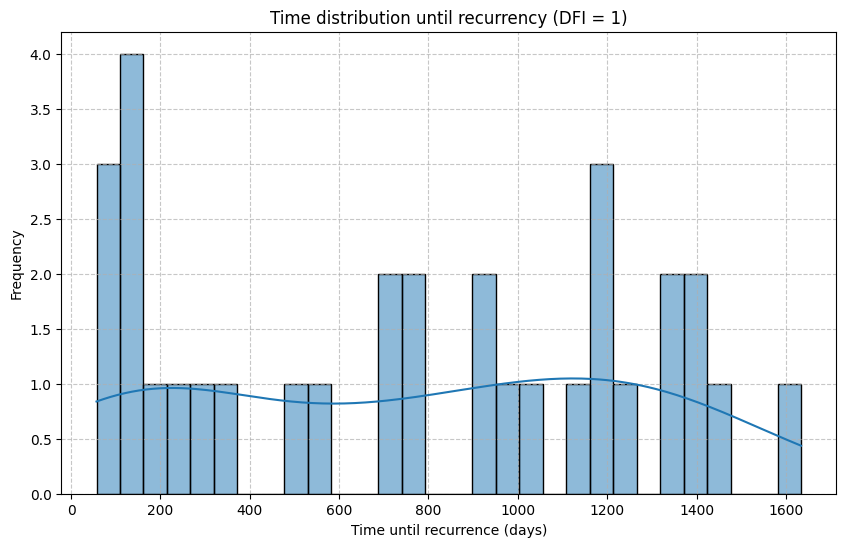

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for individuals where DFI == 1 (recurrence occurred)
recurrence_data = PRAD_surv[PRAD_surv['DFI'] == 1]

# Plot the distribution of 'DFI.time' for these individuals
plt.figure(figsize=(10, 6))
sns.histplot(recurrence_data['DFI.time'], bins=30, kde=True)
plt.title('Time distribution until recurrency (DFI = 1)')
plt.xlabel('Time until recurrence (days)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [39]:
recurrency_3y_condition = (
    (PRAD_surv["DFI"] == 1) &
    (PRAD_surv["DFI.time"] <= 1095) # 3 años = 1095 días
)

num_recurrency_3y = recurrency_3y_condition.sum()
print(f"Number of patients with recurrency in less than 3 years: {num_recurrency_3y}")

Number of patients with recurrency in less than 3 years: 21


In [40]:
PRAD_surv['recurrency_3y'] = (PRAD_surv['DFI'] == 1) & (PRAD_surv['DFI.time'] <= 1095)

display(PRAD_surv.head())

,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction,recurrencia_3y,recurrency_3y
7,TCGA-2A-AAYF-01,TCGA-2A-AAYF,0,1364,0.0,1364,0.0,1364.0,0,1364,NaN,False,False
8,TCGA-2A-AAYO-01,TCGA-2A-AAYO,0,1272,0.0,1272,0.0,1272.0,0,1272,NaN,False,False
10,TCGA-4L-AA1F-01,TCGA-4L-AA1F,0,350,0.0,350,0.0,350.0,0,350,NaN,False,False
12,TCGA-CH-5738-01,TCGA-CH-5738,0,212,0.0,212,0.0,212.0,0,212,NaN,False,False
13,TCGA-CH-5739-01,TCGA-CH-5739,0,671,0.0,671,0.0,671.0,0,671,NaN,False,False
